# Paso 9 · Integración con Big Data (PySpark)

| | |
|---|---|
| **IDs del enunciado** | IA3.6 (Big Data con Spark), F3, F5 |
| **Fase** | F3 · Analizar y modelar y F5 · Desplegar (CRISP-DM: *Data Preparation*, *Modeling* y *Deployment*) |
| **Historia** | HU-09 · Sprint S6 |
| **Entregables** | este notebook + `Back/models/resultados_spark.json` + Parquet particionado en `db/processed/spark/` |
| **Entorno** | contenedor `quay.io/jupyter/pyspark-notebook:2026-10-19` (Spark 4.2, Java 21) definido en `Back/docker-compose.spark.yml` (ADR-005) |

**Objetivo.** Repetir con **PySpark** el flujo del proyecto (lectura, limpieza, variables derivadas,
agregaciones, almacenamiento columnar, modelo y *scoring*) para mostrar que la solución escala sin
reescribirse: el mismo código corre en un portátil (`local[*]`) o en un clúster (`--master yarn`).

**Aprendizaje de la unidad (Módulo 2 · Unidad 3).**
- *Conceptual:* Spark reparte un `DataFrame` en **particiones** que se procesan en paralelo; las
  transformaciones son **perezosas** (construyen un plan, un DAG) y solo las **acciones** (`count`,
  `write`, `toPandas`) lo ejecutan. El almacenamiento columnar y particionado (Parquet) es la base de un
  *data lake*: permite leer solo las columnas y particiones que se necesitan.
- *Práctico:* esquema explícito con `StructType`, `filter`/`select`/`withColumn`/`groupBy().agg()`,
  Spark SQL sobre vistas temporales, escritura `partitionBy`, un `Pipeline` de **MLlib** evaluado con
  `BinaryClassificationEvaluator` y comparado con scikit-learn sobre el **mismo test**, y un *scoring*
  por lotes que guarda sus predicciones en Parquet.

In [1]:
FAST = False

In [2]:
# Parameters
FAST = False


In [3]:
from credit_risk.notebook import setup

ENTORNO = setup()
ENTORNO

{'entorno': 'Jupyter local',
 'kernel': 'credit-risk',
 'semilla': 42,
 'versiones': {'python': '3.13.16',
  'pandas': '2.3.3',
  'numpy': '2.5.4',
  'matplotlib': '3.11.2',
  'seaborn': '0.13.2',
  'scikit-learn': '1.9.1',
  'duckdb': '2.0.0',
  'plotnine': 'no instalada'}}

In [4]:
import re
import shutil
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression as LogisticRegressionSpark
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import Imputer, OneHotEncoder, SQLTransformer, StandardScaler, StringIndexer, VectorAssembler
from pyspark.ml.functions import vector_to_array
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql import types as T

from credit_risk import config
from credit_risk.data import cargar_procesados, separar_xy
from credit_risk.features import build_pipeline, crear_variables
from credit_risk.models import catalogo, curvas, metricas, umbrales_chow
from credit_risk.notebook import ruta
from credit_risk.reporting import PALETA, SERIE, figura_front
from credit_risk.schemas_resultados import FilaModelo, Metricas, ResultadosSpark, guardar_resultados

spark = (SparkSession.builder.master("local[*]").appName("riesgo-credito-nb09")
         .config("spark.driver.memory", "2g")
         .config("spark.ui.enabled", "false")                # sin interfaz web: el contenedor solo ejecuta
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.sql.shuffle.partitions", "8")        # 12 mil filas: 200 particiones de shuffle sobran
         .config("spark.sql.session.timeZone", "UTC")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
sc = spark.sparkContext
UMBRALES = umbrales_chow()
UMBRAL = UMBRALES.bayes
ID = config.ID_COL
# Espacio de trabajo en el disco local del contenedor (el "HDFS" de este clúster de un nodo). El montaje del
# host es lento para las muchas lecturas pequeñas de Parquet; al final se publica una copia en db/processed/spark/.
TRABAJO = Path(tempfile.gettempdir()) / "spark_nb09"
DESTINO = config.PROCESSED_DIR / "spark"
shutil.rmtree(TRABAJO, ignore_errors=True)
print(f"Spark {spark.version} · Java {sc._jvm.System.getProperty('java.version')} · master {sc.master} · "
      f"aplicación '{sc.appName}' · paralelismo por defecto {sc.defaultParallelism} núcleos")


def plan_fisico(df, hasta: str | None = None) -> str:
    """Plan físico del DataFrame, sin rutas absolutas y cortado en la primera línea que contiene ``hasta``."""
    plan = df._jdf.queryExecution().executedPlan().toString()
    plan = plan.replace(f"file:{config.PROJECT_ROOT}", ".").replace(str(config.PROJECT_ROOT), ".")
    plan = plan.replace(f"file:{TRABAJO}", "<trabajo>").replace(str(TRABAJO), "<trabajo>")
    lineas = []
    for ln in plan.splitlines():
        lineas.append(ln if len(ln) <= 120 else ln[:117] + "...")
        if hasta and hasta in ln:
            break
    return "\n".join(lineas)


def publicar(origen: Path, nombre: str) -> Path:
    """Copia un directorio Parquet de trabajo a ``db/processed/spark/<nombre>`` (sin los ``.crc`` de Hadoop)."""
    destino = DESTINO / nombre
    shutil.rmtree(destino, ignore_errors=True)
    shutil.copytree(origen, destino, ignore=shutil.ignore_patterns("*.crc", "_temporary"))
    return destino

Spark 4.2.0 · Java 21.0.12.1 · master local[*] · aplicación 'riesgo-credito-nb09' · paralelismo por defecto 8 núcleos


## 1. Lectura del CSV crudo con un esquema explícito

Declarar el esquema (en lugar de `inferSchema=True`) evita una pasada extra sobre los datos, fija los tipos
del contrato de datos (`docs/03_contrato_datos.md`) y hace que un archivo mal formado no cambie
silenciosamente el tipo de una columna. `puntaje_buro` se declara `double` porque en el crudo viene como
`805.0`.

In [5]:
# Orden de columnas del CSV (contrato de datos); los tipos salen de credit_risk.config.
COLUMNAS_CRUDO = [ID, "edad", "sexo", "estado_civil", "nivel_educativo", "situacion_laboral", "antiguedad_laboral_anios",
                  "personas_a_cargo", "tipo_vivienda", "ingreso_mensual", "monto_credito", "plazo_meses",
                  "tasa_interes_anual", "proposito", "num_creditos_activos", "moras_ultimos_12m",
                  "relacion_deuda_ingreso", "puntaje_buro", "uso_cupo_tarjetas", config.TEXT_COL, config.TARGET]
ENTEROS = {"edad", "personas_a_cargo", "plazo_meses", "num_creditos_activos", "moras_ultimos_12m", config.TARGET}


def tipo_spark(col: str) -> T.DataType:
    if col in ENTEROS:
        return T.IntegerType()
    return T.DoubleType() if col in config.NUM_COLS_RAW else T.StringType()


ESQUEMA = T.StructType([T.StructField(c, tipo_spark(c), nullable=True) for c in COLUMNAS_CRUDO])
crudo = (spark.read.schema(ESQUEMA)
         .option("header", True).option("quote", '"').option("escape", '"').option("mode", "PERMISSIVE")
         .csv(str(config.RAW_DATA_PATH))
         .withColumn("orden_archivo", F.monotonically_increasing_id()))  # para "conservar la primera" fila
print(f"Origen: {ruta(config.RAW_DATA_PATH)} · particiones de lectura: {crudo.rdd.getNumPartitions()}")
crudo.printSchema()

Origen: db/credit_risk.csv · particiones de lectura: 1
root
 |-- id_cliente: string (nullable = true)
 |-- edad: integer (nullable = true)
 |-- sexo: string (nullable = true)
 |-- estado_civil: string (nullable = true)
 |-- nivel_educativo: string (nullable = true)
 |-- situacion_laboral: string (nullable = true)
 |-- antiguedad_laboral_anios: double (nullable = true)
 |-- personas_a_cargo: integer (nullable = true)
 |-- tipo_vivienda: string (nullable = true)
 |-- ingreso_mensual: double (nullable = true)
 |-- monto_credito: double (nullable = true)
 |-- plazo_meses: integer (nullable = true)
 |-- tasa_interes_anual: double (nullable = true)
 |-- proposito: string (nullable = true)
 |-- num_creditos_activos: integer (nullable = true)
 |-- moras_ultimos_12m: integer (nullable = true)
 |-- relacion_deuda_ingreso: double (nullable = true)
 |-- puntaje_buro: double (nullable = true)
 |-- uso_cupo_tarjetas: double (nullable = true)
 |-- texto_solicitud: string (nullable = true)
 |-- defaul

In [6]:
n_crudo = crudo.count()
print(f"Filas leídas: {n_crudo:,} · columnas: {len(crudo.columns) - 1}")
NUM_DESCRIBE = ["edad", "ingreso_mensual", "monto_credito", "plazo_meses", "tasa_interes_anual", "puntaje_buro",
                "moras_ultimos_12m", config.TARGET]
describe = crudo.select(NUM_DESCRIBE).describe().toPandas().set_index("summary")
describe.apply(pd.to_numeric).T

Filas leídas: 12,144 · columnas: 21


summary,count,mean,stddev,min,max
edad,"12,144.0000",49.1309,23.6457,1.0000,999.0000
ingreso_mensual,"11,395.0000","2,624,177.0952","2,035,883.6825","312,000.0000","64,540,000.0000"
monto_credito,"12,144.0000","21,541,744.2358","31,447,367.7141","1,000,000.0000","1,033,300,000.0000"
plazo_meses,"12,144.0000",32.5721,19.5487,6.0000,84.0000
tasa_interes_anual,"12,144.0000",26.1203,9.2359,10.0000,42.0000
puntaje_buro,"11,656.0000",708.7564,118.3887,150.0000,950.0000
moras_ultimos_12m,"12,144.0000",0.5094,0.9109,0.0000,10.0000
default,"12,144.0000",0.3563,0.4789,0.0000,1.0000


`describe()` es una **acción**: recorre todas las particiones y devuelve un resumen pequeño al *driver*.
El conteo de filas no nulas por columna (fila `count`) ya deja ver los faltantes del crudo, y los mínimos y
máximos muestran los valores fuera de rango que la limpieza del paso 3 convierte en nulos.

## 2. Transformaciones en Spark: `filter`, `select`, `withColumn` y ventanas

Se traducen a Spark las reglas fijas de `credit_risk.data.limpiar` (catálogos, rangos válidos de
`credit_risk.config`, duplicados) y las variables derivadas de `credit_risk.features.crear_variables`
(misma fórmula de amortización francesa). Nada de esto se ejecuta todavía: Spark solo acumula el plan.

In [7]:
def normalizar_categoria(col: str, validas: list[str]):
    """Igual que en pandas: strip → espacios por '_' → minúsculas → valor del catálogo (o nulo)."""
    mapa = F.create_map(*[F.lit(x) for v in validas for x in (v.lower(), v)])
    return mapa[F.lower(F.regexp_replace(F.trim(F.col(col)), " ", "_"))]


def en_rango(col: str, lo: float, hi: float):
    """El valor si está en [lo, hi]; nulo si no (se imputará con estadísticos de train)."""
    return F.when(F.col(col).between(lo, hi), F.col(col))


primera = Window.partitionBy(ID).orderBy("orden_archivo")
limpio = (crudo
          .filter(F.col(config.TARGET).isNotNull())
          .withColumn("_n", F.row_number().over(primera)).filter(F.col("_n") == 1).drop("_n")  # duplicados de id
          .withColumns({c: normalizar_categoria(c, v) for c, v in config.CATEGORIAS.items()})
          .withColumn("edad", en_rango("edad", *config.EDAD_VALIDA))
          .withColumns({c: F.when(F.col(c) > 0, F.col(c)) for c in ["monto_credito", "ingreso_mensual"]})
          .withColumns({c: en_rango(c, lo, hi) for c, (lo, hi) in config.RANGOS_VALIDOS.items()}))

r = F.col("tasa_interes_anual") / 100 / 12
n = F.when(F.col("plazo_meses") != 0, F.col("plazo_meses"))
ingreso = F.when(F.col("ingreso_mensual") != 0, F.col("ingreso_mensual"))
edad = F.col("edad")
rango_edad = F.lit(None).cast("string")
for (lo, hi), etiqueta in zip(zip(config.RANGO_EDAD_BINS[:-1], config.RANGO_EDAD_BINS[1:]), config.RANGO_EDAD_LABELS):
    rango_edad = F.when((edad > lo) & (edad <= hi), etiqueta).otherwise(rango_edad)  # pd.cut: (lo, hi]
texto = F.coalesce(F.col(config.TEXT_COL), F.lit(""))

derivadas = (limpio
             .withColumn("cuota_estimada", F.when(r > 0, F.col("monto_credito") * r / (1 - F.pow(1 + r, -n)))
                         .otherwise(F.col("monto_credito") / n))
             .withColumn("ratio_cuota_ingreso", F.col("cuota_estimada") / ingreso)
             .withColumn("ratio_monto_ingreso", F.col("monto_credito") / ingreso)
             .withColumn("rango_edad", rango_edad)
             .withColumn("tiene_moras_previas", F.when(F.col("moras_ultimos_12m") > 0, 1).otherwise(0))
             .withColumn("longitud_texto", F.length(F.when(texto == config.TEXTO_FALTANTE, "").otherwise(texto)))
             # códigos ordinales (mismo orden que config.ORDINALES): entran al modelo como números
             .withColumns({f"{c}_ord": F.create_map(*[F.lit(x) for i, v in enumerate(niveles) for x in (v, i)])[F.col(c)]
                           .cast("double") for c, niveles in config.ORDINALES.items()})
             .drop("orden_archivo"))
derivadas = derivadas.cache()  # se reutiliza en agregaciones, SQL, Parquet y modelo
n_limpio = derivadas.count()   # acción: materializa la caché
print(f"Filas tras quitar duplicados de {ID}: {n_limpio:,} (se descartaron {n_crudo - n_limpio:,})")
derivadas.select(ID, "monto_credito", "plazo_meses", "tasa_interes_anual", "ingreso_mensual", "cuota_estimada",
                 "ratio_cuota_ingreso", "rango_edad", "tiene_moras_previas", config.TARGET).limit(5).toPandas()

Filas tras quitar duplicados de id_cliente: 12,000 (se descartaron 144)


,id_cliente,monto_credito,plazo_meses,tasa_interes_anual,ingreso_mensual,cuota_estimada,ratio_cuota_ingreso,rango_edad,tiene_moras_previas,default
0,CLI_000012,"5,799,000.0000",12,38.4000,NaN,"589,556.6828",NaN,>60,0,0
1,CLI_000013,"15,088,000.0000",36,31.7000,"4,524,000.0000","654,638.7584",0.1447,>60,0,1
2,CLI_000019,"7,592,000.0000",24,27.5000,"2,114,000.0000","414,781.6161",0.1962,>60,0,0
3,CLI_000029,"8,660,000.0000",24,11.0000,"2,465,000.0000","403,623.8788",0.1637,46-60,0,0
4,CLI_000035,"118,947,000.0000",48,33.9000,"3,636,000.0000","4,556,768.7729",1.2532,>60,0,0


**Verificación contra el paquete.** La traducción a Spark debe dar exactamente lo mismo que
`credit_risk.features.crear_variables` aplicada a las mismas filas limpias. Se comparan las cuatro
variables derivadas que entran al modelo, y el número de filas con los conjuntos procesados del paso 3.

In [8]:
muestra = derivadas.toPandas()
ref = crear_variables(muestra.drop(columns=["cuota_estimada", "ratio_cuota_ingreso", "ratio_monto_ingreso",
                                            "rango_edad", "tiene_moras_previas", "longitud_texto"]))
diferencias = {}
for c in ["cuota_estimada", "ratio_cuota_ingreso", "ratio_monto_ingreso", "tiene_moras_previas", "longitud_texto"]:
    a, b = muestra[c].astype(float).to_numpy(), ref[c].astype(float).to_numpy()
    diferencias[c] = {"nulos_spark": int(np.isnan(a).sum()), "nulos_pandas": int(np.isnan(b).sum()),
                      "filas_distintas": int((~np.isclose(a, b, rtol=1e-9, atol=0, equal_nan=True)).sum())}
diferencias["rango_edad"] = {"nulos_spark": int(muestra["rango_edad"].isna().sum()),
                             "nulos_pandas": int(ref["rango_edad"].isna().sum()),
                             "filas_distintas": int((muestra["rango_edad"].fillna("") != ref["rango_edad"].fillna("")).sum())}
train_pd, test_pd = cargar_procesados()
print(f"Filas limpias en Spark: {n_limpio:,} · train + test procesados (paso 3): {len(train_pd) + len(test_pd):,}")
pd.DataFrame(diferencias).T

Filas limpias en Spark: 12,000 · train + test procesados (paso 3): 12,000


,nulos_spark,nulos_pandas,filas_distintas
cuota_estimada,0,0,0
ratio_cuota_ingreso,739,739,0
ratio_monto_ingreso,739,739,0
tiene_moras_previas,0,0,0
longitud_texto,0,0,0
rango_edad,24,24,0


### `groupBy().agg()`: tasa de impago por segmento

La agregación provoca un *shuffle*: cada partición calcula sumas parciales por grupo y Spark las reúne por
clave (el `Exchange hashpartitioning` del plan físico que se imprime abajo).

In [9]:
def tasa_por(dimension: str):
    return (derivadas.groupBy(dimension)
            .agg(F.count("*").alias("solicitudes"), F.sum(config.TARGET).alias("impagos"),
                 F.avg(config.TARGET).alias("tasa_impago"), F.avg("ratio_cuota_ingreso").alias("ratio_cuota_medio"),
                 F.percentile_approx("monto_credito", 0.5).alias("monto_mediano"))
            .withColumnRenamed(dimension, "segmento").withColumn("dimension", F.lit(dimension))
            .orderBy(F.desc("tasa_impago")))


por_proposito = tasa_por("proposito")
print(plan_fisico(por_proposito, hasta="InMemoryTableScan"))
segmentos = pd.concat([tasa_por(d).toPandas() for d in ["proposito", "situacion_laboral"]], ignore_index=True)
segmentos["segmento"] = segmentos["segmento"].fillna("Sin dato")
tasa_global = float(derivadas.agg(F.avg(config.TARGET)).first()[0])
segmentos

AdaptiveSparkPlan isFinalPlan=false
+- Sort [tasa_impago#2855 DESC NULLS LAST], true, 0
   +- Exchange rangepartitioning(tasa_impago#2855 DESC NULLS LAST, 8), ENSURE_REQUIREMENTS, [plan_id=307]
      +- ObjectHashAggregate(keys=[proposito#751], functions=[count(1), sum(default#20), avg(default#20), avg(ratio_c...
         +- Exchange hashpartitioning(proposito#751, 8), ENSURE_REQUIREMENTS, [plan_id=304]
            +- ObjectHashAggregate(keys=[proposito#751], functions=[partial_count(1), partial_sum(default#20), partia...
               +- InMemoryTableScan [monto_credito#754, proposito#751, default#20, ratio_cuota_ingreso#762]


,segmento,solicitudes,impagos,tasa_impago,ratio_cuota_medio,monto_mediano,dimension
0,Vivienda,1707,726,0.4253,1.5752,"55,057,000.0000",proposito
1,Consolidacion_deuda,1945,724,0.3722,0.2602,"8,884,000.0000",proposito
2,Negocio,1677,621,0.3703,0.4003,"13,968,000.0000",proposito
3,Vehiculo,2090,754,0.3608,0.5055,"18,480,000.0000",proposito
4,Educacion,1193,386,0.3236,0.3255,"10,814,000.0000",proposito
5,Libre_inversion,3388,1057,0.3120,0.2116,"7,216,000.0000",proposito
6,Desempleado,799,496,0.6208,0.4969,"5,427,000.0000",situacion_laboral
7,Independiente,3254,1273,0.3912,0.4997,"12,597,000.0000",situacion_laboral
8,Empleado,6360,2078,0.3267,0.5074,"13,004,000.0000",situacion_laboral
9,Sin dato,485,158,0.3258,0.4934,"12,231,000.0000",situacion_laboral


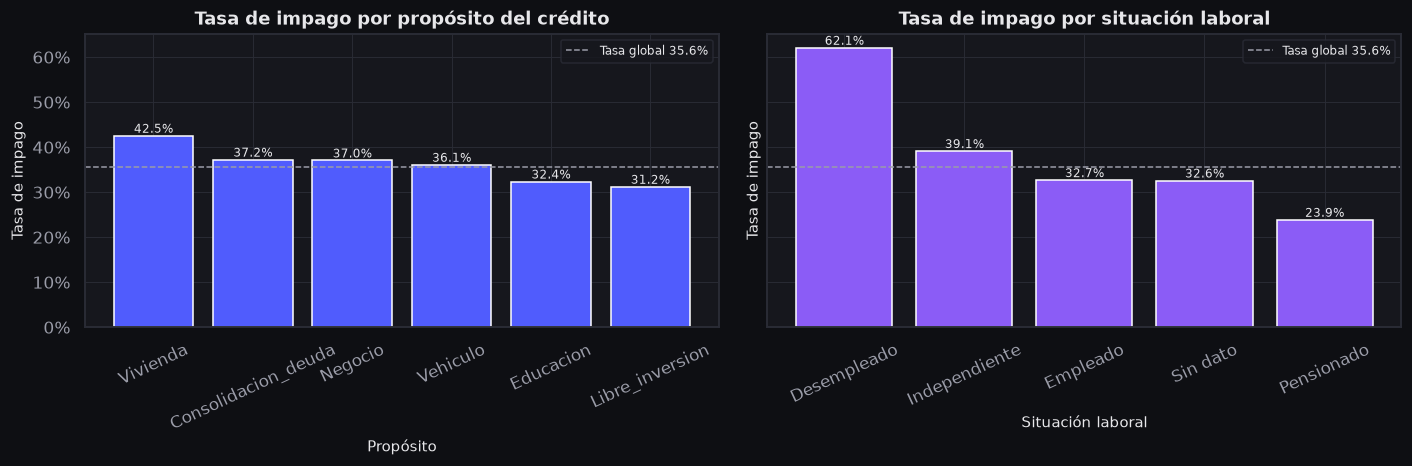

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, (dim, titulo, eje_x) in zip(axes, [("proposito", "Tasa de impago por propósito del crédito", "Propósito"),
                                          ("situacion_laboral", "Tasa de impago por situación laboral", "Situación laboral")]):
    t = segmentos[segmentos["dimension"] == dim].sort_values("tasa_impago", ascending=False)
    barras = ax.bar(t["segmento"], t["tasa_impago"], color=SERIE[0] if dim == "proposito" else SERIE[3])
    ax.axhline(tasa_global, ls="--", lw=1, color=PALETA["texto_suave"], label=f"Tasa global {tasa_global:.1%}")
    ax.bar_label(barras, labels=[f"{v:.1%}" for v in t["tasa_impago"]], fontsize=8, color=PALETA["texto"])
    ax.set(title=titulo, xlabel=eje_x, ylabel="Tasa de impago")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.tick_params(axis="x", rotation=25)
    ax.legend(fontsize=8, loc="upper right")
    figura_front("barras", titulo,
                 {"categorias": t["segmento"].tolist(),
                  "series": [{"nombre": "Tasa de impago", "valores": t["tasa_impago"].round(4).tolist()}],
                  "referencias": [{"eje": "y", "valor": round(tasa_global, 4), "etiqueta": "Tasa global"}]},
                 ejes={"x": eje_x, "y": "Tasa de impago"}, clave=f"spark_tasa_impago_por_{dim}",
                 nota="Calculado con groupBy().agg() en Spark sobre las solicitudes limpias.",
                 opciones={"formato_y": "pct"})
plt.show()

**Interpretación.** La línea punteada es la tasa global (35,6 %). Por propósito, *Vivienda* es el segmento más
riesgoso (42,5 %) y *Libre inversión* el menos (31,2 %); los demás quedan entre 32 % y 37 %. Vivienda es también
el propósito con montos más altos (mediana de 55 millones frente a 7–18 millones del resto) y con la mayor relación
cuota/ingreso media (1,58, una media sensible a montos extremos que el modelo recorta con el capping p1–p99). La
situación laboral separa más: los desempleados incumplen el 62,1 % de las veces, 2,6 veces más que los pensionados
(23,9 %); las 485 solicitudes sin dato laboral se comportan como las de los empleados (32,6 % frente a 32,7 %).

## 3. Spark SQL sobre una vista temporal

El mismo `DataFrame` se registra como vista y se consulta con SQL estándar. Spark SQL y la API de
`DataFrame` comparten el optimizador (Catalyst): ambas generan el mismo tipo de plan.

In [11]:
derivadas.createOrReplaceTempView("solicitudes")
consulta = spark.sql("""
    SELECT CASE WHEN puntaje_buro IS NULL THEN 'Sin dato'
                WHEN puntaje_buro < 550 THEN '1. < 550'
                WHEN puntaje_buro < 650 THEN '2. 550-649'
                WHEN puntaje_buro < 750 THEN '3. 650-749'
                ELSE '4. >= 750' END                         AS banda_buro,
           tiene_moras_previas,
           COUNT(*)                                          AS solicitudes,
           ROUND(AVG(`default`), 4)                          AS tasa_impago,
           ROUND(AVG(ratio_cuota_ingreso), 4)                AS ratio_cuota_medio
    FROM solicitudes
    GROUP BY 1, 2
    HAVING COUNT(*) >= 30
    ORDER BY banda_buro, tiene_moras_previas
""")
tabla_sql = consulta.toPandas()
tabla_sql

,banda_buro,tiene_moras_previas,solicitudes,tasa_impago,ratio_cuota_medio
0,1. < 550,0,145,0.7724,0.4762
1,1. < 550,1,927,0.9061,0.5039
2,2. 550-649,0,1029,0.5403,0.5171
3,2. 550-649,1,1275,0.7020,0.4848
4,3. 650-749,0,2651,0.2957,0.5060
5,3. 650-749,1,1108,0.4188,0.4802
6,4. >= 750,0,3836,0.0912,0.5171
7,4. >= 750,1,550,0.1873,0.4719
8,Sin dato,0,314,0.2197,0.5199
9,Sin dato,1,165,0.5758,0.4839


La consulta cruza dos señales de riesgo del buró: la banda de puntaje y si hubo moras en los últimos 12
meses. `HAVING COUNT(*) >= 30` descarta celdas con muy pocas solicitudes para que ninguna tasa se apoye en
un puñado de casos.

## 4. Almacenamiento columnar: Parquet particionado por `proposito`

`partitionBy("proposito")` crea una carpeta por valor (`proposito=Vivienda/`, ...). Es la misma idea con la
que se organiza un *data lake* sobre HDFS o S3: una consulta que filtra por propósito solo lee su carpeta
(*partition pruning*) y, al ser columnar, solo las columnas que usa.

Spark escribe en el disco local del contenedor (como escribiría en el HDFS del clúster) y después se publica
una copia del resultado en `db/processed/spark/`, sin los `.crc` de control de Hadoop.

In [12]:
RUTA_SOLICITUDES = TRABAJO / "solicitudes"
t0 = time.perf_counter()
# repartition por la misma columna: un archivo por carpeta (evita el problema de los "archivos pequeños")
derivadas.repartition("proposito").write.mode("overwrite").partitionBy("proposito").parquet(str(RUTA_SOLICITUDES))
t_escritura = time.perf_counter() - t0
publicado_solicitudes = publicar(RUTA_SOLICITUDES, "solicitudes")
carpetas = sorted(p for p in publicado_solicitudes.iterdir() if p.is_dir())
inventario = pd.DataFrame([{"carpeta": p.name, "archivos_parquet": len(list(p.glob("*.parquet"))),
                            "kb": round(sum(f.stat().st_size for f in p.glob("*.parquet")) / 1024, 1)}
                           for p in carpetas])
print(f"Escritura Spark: {t_escritura:.1f} s · {len(carpetas)} particiones · publicado en {ruta(publicado_solicitudes)}/")
print("Contenido:", sorted(p.name for p in publicado_solicitudes.iterdir()))
inventario

Escritura Spark: 4.2 s · 6 particiones · publicado en db/processed/spark/solicitudes/
Contenido: ['_SUCCESS', 'proposito=Consolidacion_deuda', 'proposito=Educacion', 'proposito=Libre_inversion', 'proposito=Negocio', 'proposito=Vehiculo', 'proposito=Vivienda']


,carpeta,archivos_parquet,kb
0,proposito=Consolidacion_deuda,1,132.4000
1,proposito=Educacion,1,90.1000
2,proposito=Libre_inversion,1,209.4000
3,proposito=Negocio,1,119.1000
4,proposito=Vehiculo,1,141.7000
5,proposito=Vivienda,1,121.1000


Leído de vuelta: 12,000 filas · 29 columnas (proposito vuelve como columna)


Filtro proposito = 'Vivienda' → PartitionFilters: [isnotnull(proposito#7378), (proposito#7378 = Vivienda)] · filas leídas: 1,707


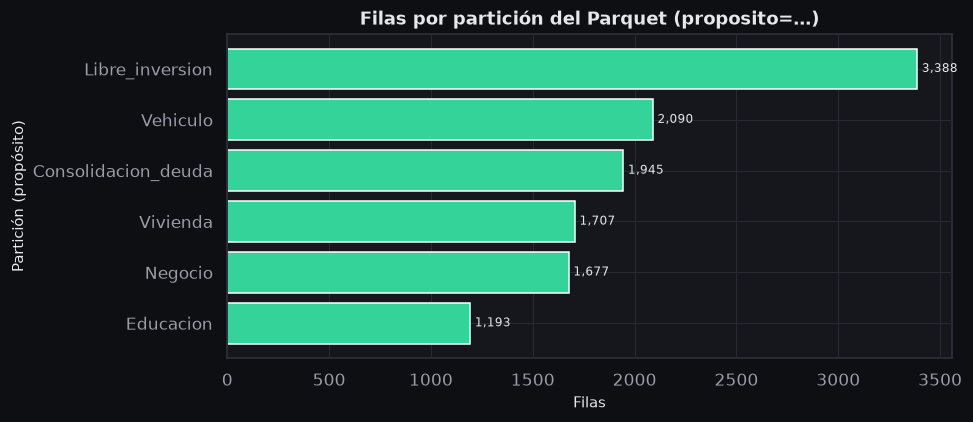

In [13]:
lago = spark.read.parquet(str(RUTA_SOLICITUDES))  # sin cache(): así el plan muestra la poda de particiones
conteo_particiones = lago.groupBy("proposito").count().orderBy(F.desc("count")).toPandas()
conteo_particiones.columns = ["proposito", "filas"]
solo_vivienda = spark.read.parquet(str(RUTA_SOLICITUDES)).filter(F.col("proposito") == "Vivienda")
filtro_particion = re.search(r"PartitionFilters: \[[^\]]*\]", solo_vivienda._jdf.queryExecution().executedPlan().toString())
print(f"Leído de vuelta: {lago.count():,} filas · {len(lago.columns)} columnas (proposito vuelve como columna)")
print(f"Filtro proposito = 'Vivienda' → {filtro_particion.group(0) if filtro_particion else 'sin PartitionFilters'} · "
      f"filas leídas: {solo_vivienda.count():,}")

fig, ax = plt.subplots(figsize=(9, 4))
barras = ax.barh(conteo_particiones["proposito"], conteo_particiones["filas"], color=SERIE[2])
ax.bar_label(barras, labels=[f"{v:,}" for v in conteo_particiones["filas"]], fontsize=8, color=PALETA["texto"], padding=3)
ax.invert_yaxis()
ax.set(title="Filas por partición del Parquet (proposito=…)", xlabel="Filas", ylabel="Partición (propósito)")
figura_front("barras_h", "Filas por partición del Parquet (proposito=…)",
             {"categorias": conteo_particiones["proposito"].tolist(),
              "series": [{"nombre": "Filas", "valores": conteo_particiones["filas"].astype(int).tolist()}]},
             ejes={"x": "Filas", "y": "Partición (propósito)"}, clave="spark_filas_por_particion",
             nota="Leído de vuelta del Parquet particionado en db/processed/spark/solicitudes.",
             opciones={"formato_x": "num"})
plt.show()

**Interpretación.** Las seis carpetas suman las 12.000 solicitudes limpias: *Libre inversión* es la mayor (3.388
filas, 28 %) y *Educación* la menor (1.193). Gracias a `repartition("proposito")` antes de escribir, cada carpeta
tiene un único archivo Parquet (de 90 a 210 KB) en lugar de un archivo por tarea. El plan de la consulta
`proposito = 'Vivienda'` muestra el filtro en `PartitionFilters`: Spark solo abre la carpeta `proposito=Vivienda`
y lee sus 1.707 filas. En un clúster, particiones tan desiguales como estas (casi 3 a 1) harían que unas tareas
tarden más que otras (*data skew*); a esta escala no tiene efecto.

## 5. HDFS, YARN y MapReduce frente a Spark

| Pieza | Rol en el ecosistema Hadoop | Qué hace Spark | Aquí (Docker, `local[*]`) |
|---|---|---|---|
| **HDFS** | Sistema de archivos distribuido: parte cada archivo en bloques (128 MB) replicados (×3) en varios nodos. | Spark **no** almacena: lee y escribe en HDFS, S3, ADLS o disco local. | Disco local montado; el Parquet particionado imita la organización de un *data lake*. |
| **YARN** | Gestor de recursos del clúster: asigna contenedores (CPU, memoria) a las aplicaciones. | Spark pide *executors* a YARN (o a Kubernetes / Standalone). | Un solo proceso: el *driver* hace también de *executor* con todos los núcleos. |
| **MapReduce** | Modelo de cómputo en dos fases (map → shuffle → reduce) que escribe a disco entre cada trabajo. | Sustituye a MapReduce: un **DAG** de etapas que mantiene los datos intermedios **en memoria**. | Las agregaciones de arriba son un map + shuffle + reduce dentro de un único DAG. |

**Por qué Spark es más rápido que MapReduce para este tipo de trabajo:**
- **DAG y optimizador.** Una cadena de `filter → withColumn → groupBy` se compila en un único plan con
  etapas separadas solo donde hay *shuffle*; Catalyst reordena filtros, poda columnas y elige la estrategia
  de *join*. MapReduce encadenaría varios trabajos independientes.
- **Memoria.** `cache()` guarda las particiones en RAM para reutilizarlas (aquí: agregaciones, SQL, Parquet y
  modelo leen la misma caché). MapReduce relee y reescribe HDFS entre trabajos; los algoritmos iterativos
  (como la regresión logística, que recorre los datos en cada iteración) son donde más se nota.
- **Evaluación perezosa.** `withColumn` o `filter` no tocan los datos; solo una **acción** (`count`, `write`,
  `toPandas`) dispara el cálculo, lo que permite optimizar el plan completo antes de ejecutarlo.

**Cómo escalaría este notebook en un clúster.** El código no cambia: se lanza con
`spark-submit --master yarn --deploy-mode cluster --num-executors N --executor-memory 8g`, el origen pasa a
ser `hdfs:///datalake/credito/solicitudes/` o `s3a://…`, y `spark.sql.shuffle.partitions` se ajusta al
volumen (aquí 8, porque son 12 mil filas). Con millones de solicitudes, el particionado por propósito (y por
fecha de solicitud) permitiría que el *scoring* nocturno lea solo las particiones nuevas.

## 6. Spark MLlib: `Pipeline` de regresión logística

Para que la comparación con scikit-learn sea justa, MLlib entrena con **las mismas solicitudes de train** y
se evalúa en **el mismo test** que el resto del proyecto: los `id_cliente` de `db/processed/train.csv` y
`test.csv` (paso 3) se unen con las solicitudes leídas del Parquet (`left_semi` *join*).

Etapas del `Pipeline`: `SQLTransformer` (capping p1–p99 con límites de train, como el `Winsorizer` del
paquete) → `Imputer` (mediana en numéricas, moda en ordinales) → `StringIndexer` → `OneHotEncoder` →
`VectorAssembler` → `StandardScaler` → `LogisticRegression` con la misma regularización L2 que la de
scikit-learn (`C = 1` ⇔ `regParam = 1 / n_train`).

In [14]:
ids_train = spark.createDataFrame(train_pd[[ID]])
ids_test = spark.createDataFrame(test_pd[[ID, config.TARGET]].rename(columns={config.TARGET: "default_paso3"}))
tr = lago.join(ids_train, ID, "left_semi")
te = lago.join(ids_test, ID, "inner")
n_tr_total, n_te = tr.count(), te.count()
etiquetas_distintas = te.filter(F.col(config.TARGET) != F.col("default_paso3")).count()
te = te.drop("default_paso3")
if FAST:  # prueba de humo: ~3.000 filas de train
    tr = tr.sample(fraction=3000 / n_tr_total, seed=config.RANDOM_STATE)
tr, te = tr.cache(), te.cache()
n_tr = tr.count()
print(f"train Spark: {n_tr:,} filas (de {n_tr_total:,}; paso 3: {len(train_pd):,}) · test Spark: {n_te:,} filas "
      f"(paso 3: {len(test_pd):,}) · etiquetas distintas a las del paso 3: {etiquetas_distintas}")

train Spark: 9,600 filas (de 9,600; paso 3: 9,600) · test Spark: 2,400 filas (paso 3: 2,400) · etiquetas distintas a las del paso 3: 0


In [15]:
NUMERICAS = config.NUM_MODELO
ORDINALES = [f"{c}_ord" for c in config.ORDINALES]
NOMINALES = config.CAT_NOMINALES
cuantiles = tr.approxQuantile(config.COLS_CAPPING, list(config.CAPPING_QUANTILES), 0.0)
limites = dict(zip(config.COLS_CAPPING, cuantiles))
cap = SQLTransformer(statement="SELECT *, " + ", ".join(
    f"LEAST(GREATEST({c}, {lo!r}), {hi!r}) AS {c}_cap" for c, (lo, hi) in limites.items()) + " FROM __THIS__")
entrada_num = [f"{c}_cap" if c in limites else c for c in NUMERICAS]
etapas = [
    cap,
    Imputer(strategy="median", inputCols=entrada_num, outputCols=[f"{c}_imp" for c in NUMERICAS]),
    Imputer(strategy="mode", inputCols=ORDINALES, outputCols=[f"{c}_imp" for c in ORDINALES]),
    StringIndexer(inputCols=NOMINALES, outputCols=[f"{c}_idx" for c in NOMINALES], handleInvalid="keep",
                  stringOrderType="alphabetAsc"),
    OneHotEncoder(inputCols=[f"{c}_idx" for c in NOMINALES], outputCols=[f"{c}_ohe" for c in NOMINALES],
                  handleInvalid="keep"),
    VectorAssembler(inputCols=[f"{c}_imp" for c in NUMERICAS + ORDINALES] + [f"{c}_ohe" for c in NOMINALES],
                    outputCol="variables"),
    StandardScaler(inputCol="variables", outputCol="variables_esc", withMean=True, withStd=True),
    LogisticRegressionSpark(featuresCol="variables_esc", labelCol=config.TARGET, regParam=1 / n_tr,
                            elasticNetParam=0.0, maxIter=30 if FAST else 100, tol=1e-6, standardization=False),
]
pipeline = Pipeline(stages=etapas)
evaluador = BinaryClassificationEvaluator(labelCol=config.TARGET, rawPredictionCol="rawPrediction",
                                          metricName="areaUnderROC")

t0 = time.perf_counter()
modelo_spark = pipeline.fit(tr)
t_mllib = time.perf_counter() - t0
pred_te = modelo_spark.transform(te).cache()
auc_mllib = float(evaluador.evaluate(pred_te))
pr_mllib = float(evaluador.evaluate(pred_te, {evaluador.metricName: "areaUnderPR"}))
lr_spark = modelo_spark.stages[-1]
print(f"Ajuste en train: {t_mllib:.1f} s · {lr_spark.summary.totalIterations} iteraciones de L-BFGS · "
      f"{lr_spark.numFeatures} variables tras one-hot")
print(f"BinaryClassificationEvaluator en test → areaUnderROC {auc_mllib:.4f} · areaUnderPR {pr_mllib:.4f}")

auc_cv = auc_cv_std = None
if not FAST:  # validación cruzada del mismo Pipeline en train (comparable con la columna CV de los demás pasos)
    t0 = time.perf_counter()
    cv_spark = CrossValidator(estimator=pipeline, estimatorParamMaps=ParamGridBuilder().build(), evaluator=evaluador,
                              numFolds=config.CV_FOLDS, seed=config.RANDOM_STATE, parallelism=2).fit(tr)
    auc_cv, auc_cv_std = float(cv_spark.avgMetrics[0]), float(cv_spark.stdMetrics[0])
    print(f"CrossValidator ({config.CV_FOLDS} folds) en train: AUC {auc_cv:.4f} ± {auc_cv_std:.4f} · "
          f"{time.perf_counter() - t0:.1f} s")

Ajuste en train: 27.9 s · 39 iteraciones de L-BFGS · 40 variables tras one-hot
BinaryClassificationEvaluator en test → areaUnderROC 0.8441 · areaUnderPR 0.7684


CrossValidator (5 folds) en train: AUC 0.8556 ± 0.0056 · 71.6 s


### Comparación con scikit-learn sobre el mismo test

El lado scikit-learn es el pipeline del paquete (`build_pipeline` + la regresión logística del
`catalogo()`), entrenado con `db/processed/train.csv` dentro de este mismo contenedor. Las métricas de los
dos se calculan con `credit_risk.models.metricas` sobre las 2.400 filas de test y el umbral de 0,25 (ADR-002).

In [16]:
X_tr, y_tr = separar_xy(train_pd)
X_te, y_te = separar_xy(test_pd)
if FAST:
    X_tr, y_tr = X_tr.iloc[:2000], y_tr[:2000]
t0 = time.perf_counter()
pipe_sk = build_pipeline(catalogo()["Regresión logística"]()).fit(X_tr, y_tr)
t_sklearn = time.perf_counter() - t0
p_sklearn = pipe_sk.predict_proba(X_te)[:, 1]

prob_te = (pred_te.select(ID, vector_to_array("probability")[1].alias("p")).toPandas()
           .set_index(ID).loc[test_pd[ID], "p"].to_numpy())
m_mllib, m_sklearn = metricas(y_te, prob_te, UMBRAL), metricas(y_te, p_sklearn, UMBRAL)
auc_sklearn = m_sklearn["roc_auc"]
comparacion = pd.DataFrame({"Spark MLlib": {**m_mllib, "tiempo_entrenamiento_s": round(t_mllib, 2)},
                            "scikit-learn": {**m_sklearn, "tiempo_entrenamiento_s": round(t_sklearn, 2)}})
comparacion["diferencia"] = comparacion["Spark MLlib"] - comparacion["scikit-learn"]
print(f"Correlación de Pearson entre las probabilidades de ambos modelos en test: "
      f"{np.corrcoef(prob_te, p_sklearn)[0, 1]:.4f}")
comparacion

Correlación de Pearson entre las probabilidades de ambos modelos en test: 0.9953


,Spark MLlib,scikit-learn,diferencia
roc_auc,0.8441,0.8459,-0.0018
pr_auc,0.7686,0.7680,0.0006
ks,0.5532,0.5445,0.0087
brier,0.1493,0.1488,0.0005
accuracy,0.7304,0.7325,-0.0021
precision,0.5844,0.5860,-0.0016
recall,0.8396,0.8454,-0.0058
f1,0.6891,0.6922,-0.0031
tiempo_entrenamiento_s,27.9100,0.5000,27.4100


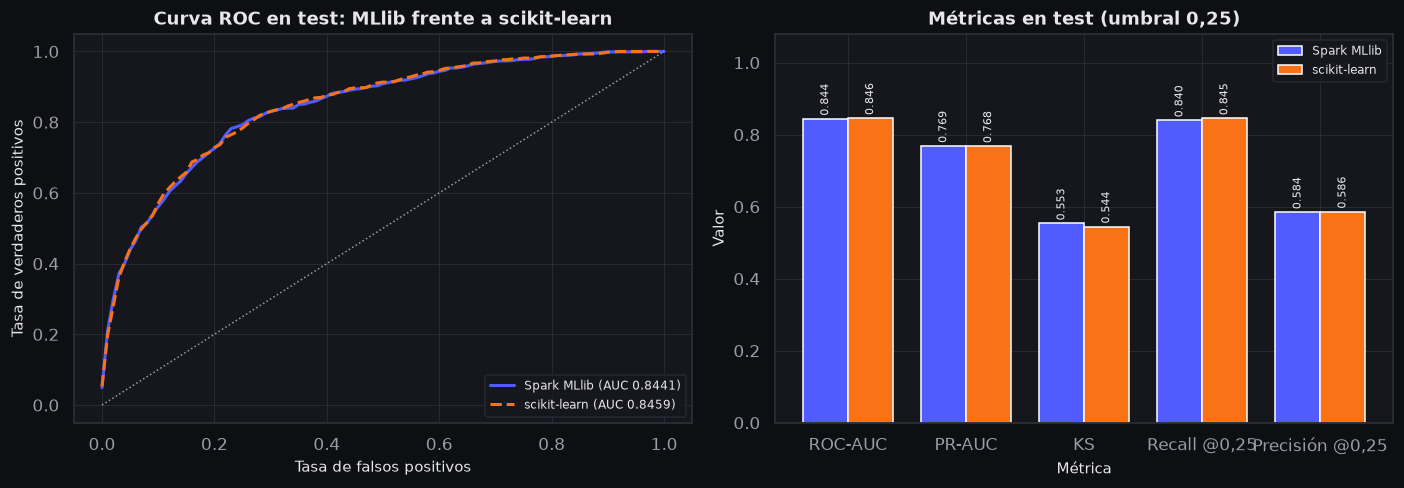

In [17]:
c_mllib, c_sklearn = curvas(y_te, prob_te), curvas(y_te, p_sklearn)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].plot(c_mllib["fpr"], c_mllib["tpr"], lw=2, color=SERIE[0], label=f"Spark MLlib (AUC {m_mllib['roc_auc']:.4f})")
axes[0].plot(c_sklearn["fpr"], c_sklearn["tpr"], lw=2, ls="--", color=SERIE[1],
             label=f"scikit-learn (AUC {m_sklearn['roc_auc']:.4f})")
axes[0].plot([0, 1], [0, 1], ls=":", lw=1, color=PALETA["texto_suave"])
axes[0].set(title="Curva ROC en test: MLlib frente a scikit-learn", xlabel="Tasa de falsos positivos",
            ylabel="Tasa de verdaderos positivos")
axes[0].legend(fontsize=8, loc="lower right")
claves = ["roc_auc", "pr_auc", "ks", "recall", "precision"]
x = np.arange(len(claves))
for i, (nombre, m, color) in enumerate([("Spark MLlib", m_mllib, SERIE[0]), ("scikit-learn", m_sklearn, SERIE[1])]):
    b = axes[1].bar(x + (i - 0.5) * 0.38, [m[k] for k in claves], width=0.38, color=color, label=nombre)
    axes[1].bar_label(b, labels=[f"{m[k]:.3f}" for k in claves], fontsize=7, color=PALETA["texto"], rotation=90, padding=2)
axes[1].set_xticks(x, ["ROC-AUC", "PR-AUC", "KS", "Recall @0,25", "Precisión @0,25"])
axes[1].set(title="Métricas en test (umbral 0,25)", xlabel="Métrica", ylabel="Valor", ylim=(0, 1.08))
axes[1].legend(fontsize=8, loc="upper right")
figura_front("curva_roc", "Curva ROC en test: MLlib frente a scikit-learn",
             {"series": [{"nombre": f"Spark MLlib (AUC {m_mllib['roc_auc']:.4f})", "x": c_mllib["fpr"], "y": c_mllib["tpr"]},
                         {"nombre": f"scikit-learn (AUC {m_sklearn['roc_auc']:.4f})", "x": c_sklearn["fpr"], "y": c_sklearn["tpr"]}]},
             ejes={"x": "Tasa de falsos positivos", "y": "Tasa de verdaderos positivos"}, clave="spark_roc_mllib_vs_sklearn",
             nota="Mismo test de 2.400 solicitudes (db/processed/test.csv).", opciones={"formato_x": "dec3", "formato_y": "dec3"})
figura_front("barras", "Métricas en test (umbral 0,25)",
             {"categorias": ["ROC-AUC", "PR-AUC", "KS", "Recall @0,25", "Precisión @0,25"],
              "series": [{"nombre": "Spark MLlib", "valores": [m_mllib[k] for k in claves]},
                         {"nombre": "scikit-learn", "valores": [m_sklearn[k] for k in claves]}]},
             ejes={"x": "Métrica", "y": "Valor"}, clave="spark_metricas_mllib_vs_sklearn", opciones={"formato_y": "dec3"})
figura_front("kpi", "AUC en test: MLlib frente a scikit-learn",
             {"items": [{"etiqueta": "AUC Spark MLlib", "valor": m_mllib["roc_auc"], "formato": "dec3"},
                        {"etiqueta": "AUC scikit-learn", "valor": m_sklearn["roc_auc"], "formato": "dec3"},
                        {"etiqueta": "Diferencia (MLlib − sklearn)", "valor": round(m_mllib["roc_auc"] - m_sklearn["roc_auc"], 4),
                         "formato": "dec3"}]},
             clave="spark_kpi_auc")
plt.show()

**Interpretación.** Las dos curvas ROC prácticamente se superponen: MLlib obtiene un AUC de 0,8441 en test y
scikit-learn 0,8459 (diferencia de −0,0018), con probabilidades casi idénticas (correlación 0,995). Es lo esperado:
ambos son la misma regresión logística con regularización L2 equivalente sobre las mismas variables. Las pequeñas
diferencias vienen del preprocesamiento (Spark imputa sobre los datos limpios sin imputar y codifica los nulos como
una categoría más, mientras que scikit-learn recibe los datos ya imputados del paso 3) y del optimizador. Al
umbral de 0,25 ambos detectan cerca del 84 % de los impagos con una precisión cercana al 58 %. La diferencia
práctica está en el tiempo: en un solo nodo MLlib tardó 27,9 s frente a 0,5 s de scikit-learn, porque cada
iteración de L-BFGS es un trabajo de Spark; esa sobrecarga solo se amortiza cuando los datos no caben en una
máquina.

## 7. *Scoring* por lotes (simulación del proceso nocturno)

En producción, un trabajo programado lee las solicitudes del *data lake*, aplica el modelo y deja las
probabilidades y la decisión (regla de Chow, ADR-002: aprobar < 0,178 ≤ revisar ≤ 0,467 < rechazar) en una
tabla para los sistemas de originación. Aquí se puntúan **todas** las solicitudes del Parquet y se guardan
en `db/processed/spark/scoring/`, particionadas por decisión.

In [18]:
RUTA_SCORING = TRABAJO / "scoring"
t0 = time.perf_counter()
p1 = vector_to_array("probability")[1]
scoring = (modelo_spark.transform(spark.read.parquet(str(RUTA_SOLICITUDES)))
           .select(ID, "proposito", p1.alias("probabilidad_impago"))
           .withColumn("decision", F.when(F.col("probabilidad_impago") < UMBRALES.aprobar, "aprobar")
                       .when(F.col("probabilidad_impago") > UMBRALES.rechazar, "rechazar").otherwise("revisar"))
           .withColumn("fecha_proceso", F.current_date())
           .withColumn("version_modelo", F.lit(f"mllib-lr-{config.MODEL_VERSION}")))
scoring.repartition("decision").write.mode("overwrite").partitionBy("decision").parquet(str(RUTA_SCORING))
t_scoring = time.perf_counter() - t0
publicado_scoring = publicar(RUTA_SCORING, "scoring")
leido = spark.read.parquet(str(RUTA_SCORING))
filas_scoring = leido.count()
resumen_scoring = (leido.groupBy("decision").agg(F.count("*").alias("solicitudes"),
                                                 F.round(F.avg("probabilidad_impago"), 4).alias("prob_media"))
                   .withColumn("porcentaje", F.round(F.col("solicitudes") / filas_scoring, 4))
                   .orderBy("prob_media").toPandas())
print(f"Puntuadas y escritas {filas_scoring:,} solicitudes en {t_scoring:.1f} s "
      f"({filas_scoring / t_scoring:,.0f} filas/s) · publicado en {ruta(publicado_scoring)}/ "
      f"{sorted(p.name for p in publicado_scoring.iterdir() if p.is_dir())}")
resumen_scoring

Puntuadas y escritas 12,000 solicitudes en 1.9 s (6,351 filas/s) · publicado en db/processed/spark/scoring/ ['decision=aprobar', 'decision=rechazar', 'decision=revisar']


,decision,solicitudes,prob_media,porcentaje
0,aprobar,4587,0.0794,0.3823
1,revisar,3565,0.3040,0.2971
2,rechazar,3848,0.7295,0.3207


El tiempo incluye leer el Parquet, transformar todas las filas con el `PipelineModel` y escribir el
resultado: es el ciclo completo que haría el trabajo nocturno. Con la regla de Chow, el 38,2 % de las solicitudes
se aprobaría, el 29,7 % iría a revisión manual (por debajo de la capacidad de revisión del 35 %, ADR-002) y el
32,1 % se rechazaría. `fecha_proceso` y `version_modelo` dejan trazabilidad de qué modelo produjo cada puntuación.

## 8. Resultados para el front y resumen

In [19]:
particiones = [{"proposito": str(r.proposito), "filas": int(r.filas)} for r in conteo_particiones.itertuples()]
tasa_segmento = [{"dimension": str(r.dimension), "segmento": str(r.segmento), "solicitudes": float(r.solicitudes),
                  "tasa_impago": round(float(r.tasa_impago), 4)} for r in segmentos.itertuples()]
fila = FilaModelo(modelo="Regresión logística (Spark MLlib)", familia="big data", roc_auc_cv=None if auc_cv is None else round(auc_cv, 4),
                  roc_auc_cv_std=None if auc_cv_std is None else round(auc_cv_std, 4), test=Metricas(**m_mllib),
                  tiempo_entrenamiento_s=round(t_mllib, 2), interpretabilidad="alta",
                  notas=(f"Spark {spark.version} local[*] en Docker. Mismos ids de train/test que el paso 3. "
                         f"AUC scikit-learn (mismo test, este contenedor): {auc_sklearn:.4f}. "
                         f"CV de MLlib con folds aleatorios no estratificados."))
res = ResultadosSpark(notebook="09_spark_big_data.ipynb", umbral_metricas=UMBRAL, modelos=[fila],
                      curvas={fila.modelo: c_mllib}, version_spark=spark.version, particiones=particiones,
                      tasa_por_segmento=tasa_segmento, auc_mllib=round(auc_mllib, 4),
                      auc_sklearn=round(auc_sklearn, 4), filas_scoring=filas_scoring)
destino_json = guardar_resultados(res, "resultados_spark")
mayor = segmentos[segmentos["dimension"] == "proposito"].iloc[0]
display(Markdown(
    f"**Resumen calculado.** Spark {spark.version} (`local[*]`, {sc.defaultParallelism} núcleos) leyó "
    f"{n_crudo:,} filas con esquema explícito y dejó {n_limpio:,} tras quitar duplicados. Parquet particionado en "
    f"{len(particiones)} carpetas `proposito=…` (escritura {t_escritura:.1f} s). Propósito con mayor tasa de impago: "
    f"**{mayor['segmento']}** ({mayor['tasa_impago']:.1%}; global {tasa_global:.1%}). MLlib: AUC test "
    f"{m_mllib['roc_auc']:.4f} (`BinaryClassificationEvaluator`: {auc_mllib:.4f}"
    f"{'' if auc_cv is None else f'; CV {auc_cv:.4f} ± {auc_cv_std:.4f}'}) "
    f"frente a scikit-learn {m_sklearn['roc_auc']:.4f} en el mismo test de {n_te:,} filas. Scoring por lotes: "
    f"{filas_scoring:,} solicitudes en {t_scoring:.1f} s. Resultados en `{ruta(destino_json)}`."))

**Resumen calculado.** Spark 4.2.0 (`local[*]`, 8 núcleos) leyó 12,144 filas con esquema explícito y dejó 12,000 tras quitar duplicados. Parquet particionado en 6 carpetas `proposito=…` (escritura 4.2 s). Propósito con mayor tasa de impago: **Vivienda** (42.5%; global 35.6%). MLlib: AUC test 0.8441 (`BinaryClassificationEvaluator`: 0.8441; CV 0.8556 ± 0.0056) frente a scikit-learn 0.8459 en el mismo test de 2,400 filas. Scoring por lotes: 12,000 solicitudes en 1.9 s. Resultados en `Back/models/resultados_spark.json`.

In [20]:
spark.stop()

## Conclusiones

1. **IA3.6 con PySpark real.** Spark 4.2.0 (Java 21) en el contenedor `pyspark-notebook` (ADR-005) leyó el CSV
   con esquema explícito (12.144 filas) y reprodujo en Spark la limpieza y las variables derivadas del paquete, con
   cero diferencias frente a `credit_risk.features.crear_variables` y las mismas 12.000 solicitudes del paso 3.
2. **Agregaciones y Spark SQL** confirman los patrones del EDA: *Vivienda* (42,5 %) y los desempleados (62,1 %)
   son los segmentos más riesgosos, y el buró y las moras previas se combinan: la tasa de impago va del 9,1 %
   (puntaje ≥ 750 sin moras) al 90,6 % (puntaje < 550 con moras).
3. **Almacenamiento tipo *data lake*:** Parquet particionado por propósito en `db/processed/spark/solicitudes/`
   (6 carpetas, un archivo cada una) y predicciones en `db/processed/spark/scoring/` particionadas por decisión;
   el filtro por la columna de partición poda carpetas (`PartitionFilters`).
4. **MLlib ≈ scikit-learn:** AUC de 0,8441 frente a 0,8459 en el mismo test de 2.400 solicitudes (validación
   cruzada de MLlib en train: 0,8556 ± 0,0056). Spark no mejora el modelo; lo que aporta es que el mismo código
   escala a un clúster. A este volumen scikit-learn entrena unas 50 veces más rápido, por eso el modelo servido
   sigue siendo el del paso 8.
5. **Scoring por lotes:** las 12.000 solicitudes se puntuaron y escribieron en 1,9 s: 38,2 % aprobar, 29,7 %
   revisar y 32,1 % rechazar, con la trazabilidad de la versión del modelo en cada fila.
6. **Cómo escalar:** el notebook corre en un solo nodo (`local[*]`) y trabaja en el disco local del contenedor,
   publicando una copia del resultado en el repositorio. En producción ese papel lo cumple HDFS o S3 y el mismo
   código se lanza con `spark-submit --master yarn`, leyendo solo las particiones nuevas en cada corrida nocturna.